GPU available: True | Using: cuda
Using Colab cache for faster access to the 'amazon-fine-food-reviews' dataset.
Total reviews: 568454
   Score                                               Text
0      5  I have bought several of the Vitality canned d...
1      1  Product arrived labeled as Jumbo Salted Peanut...
2      4  This is a confection that has been around a fe...
3      2  If you are looking for the secret ingredient i...
4      5  Great taffy at a great price.  There was a wid...


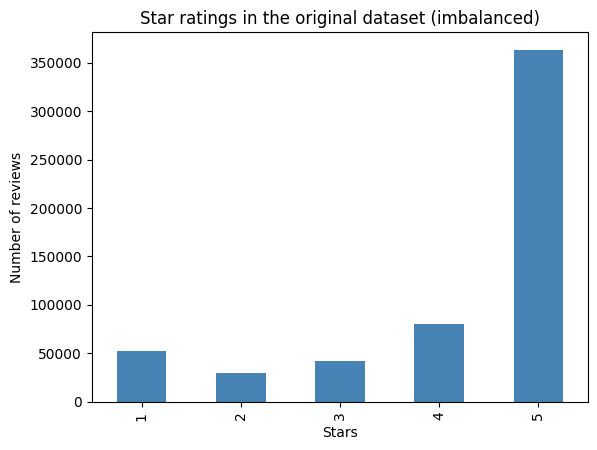

Training reviews: 4800 | Test reviews: 1200

===== Training LSTM on all training data =====
  Epoch 1/8 - loss 1.090
  Epoch 2/8 - loss 1.016
  Epoch 3/8 - loss 0.917
  Epoch 4/8 - loss 0.810
  Epoch 5/8 - loss 0.739
  Epoch 6/8 - loss 0.620
  Epoch 7/8 - loss 0.525
  Epoch 8/8 - loss 0.433

===== Fine-tuning BERT on all training data =====


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
500,0.671932



LSTM -> Accuracy: 0.570 | Macro F1: 0.573
BERT -> Accuracy: 0.743 | Macro F1: 0.744

LSTM report:
               precision    recall  f1-score   support

    negative       0.53      0.66      0.59       400
     neutral       0.48      0.49      0.49       400
    positive       0.75      0.56      0.64       400

    accuracy                           0.57      1200
   macro avg       0.59      0.57      0.57      1200
weighted avg       0.59      0.57      0.57      1200

BERT report:
               precision    recall  f1-score   support

    negative       0.72      0.78      0.75       400
     neutral       0.64      0.64      0.64       400
    positive       0.88      0.81      0.84       400

    accuracy                           0.74      1200
   macro avg       0.75      0.74      0.74      1200
weighted avg       0.75      0.74      0.74      1200



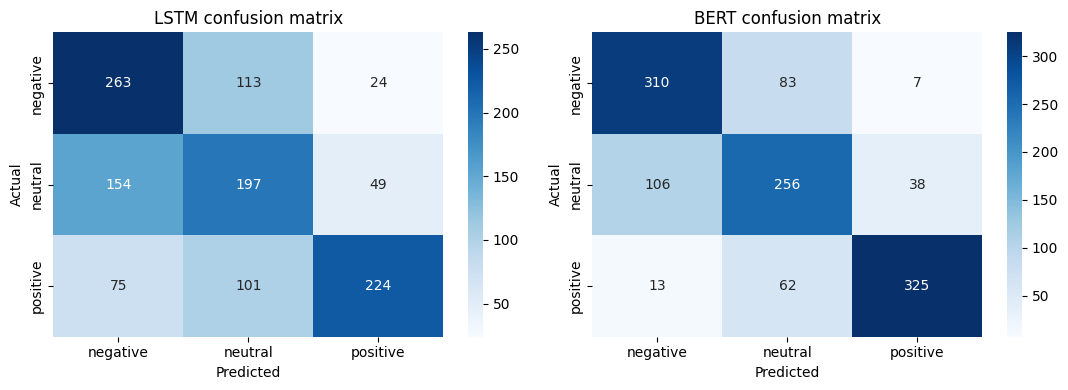


===== Low-data experiment: only 300 training reviews =====
  Epoch 1/15 - loss 1.101
  Epoch 2/15 - loss 1.079
  Epoch 3/15 - loss 1.062
  Epoch 4/15 - loss 1.045
  Epoch 5/15 - loss 1.024
  Epoch 6/15 - loss 0.998
  Epoch 7/15 - loss 0.962
  Epoch 8/15 - loss 0.922
  Epoch 9/15 - loss 0.871
  Epoch 10/15 - loss 0.782
  Epoch 11/15 - loss 0.699
  Epoch 12/15 - loss 0.587
  Epoch 13/15 - loss 0.492
  Epoch 14/15 - loss 0.376
  Epoch 15/15 - loss 0.306


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss


Accuracy with 300 reviews -> LSTM: 0.378 | BERT: 0.593


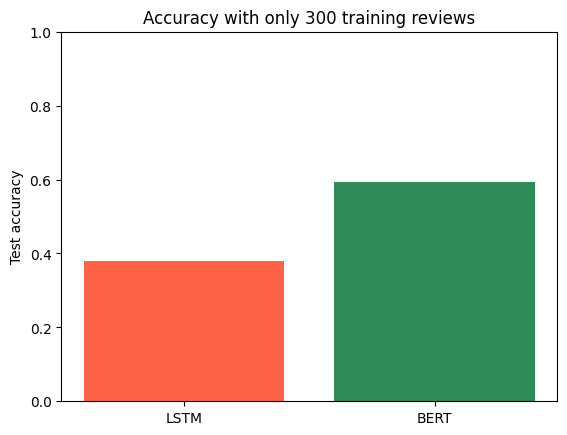


================ FINAL COMPARISON TABLE ================
            Model  Parameters (millions)  Approx size (MB)  Test accuracy  Macro F1  Accuracy with 300 reviews  Training time (sec)  Time per review (ms)
             LSTM                  0.674             2.694          0.570     0.573                      0.378                9.007                  0.65
bert-base-uncased                109.485           437.938          0.742     0.744                      0.592               80.714                 16.25

===== BERT predictions on new reviews =====
POSITIVE  (96%)  ->  Absolutely delicious, I will buy this again!
NEUTRAL   (58%)  ->  It was okay, nothing special.
NEGATIVE  (92%)  ->  Terrible taste, complete waste of money.

================ DISCUSSION ================
1. ACCURACY: BERT got 74.2% and the LSTM got 57.0% on unseen test reviews.
   Both find 'neutral' (3-star) reviews hardest because they mix good and bad opinions.
 
2. TRANSFER LEARNING EFFICIENCY:
   - BERT wa

In [1]:
# =====================================================================
# CASE STUDY 3 (Beginner, PyTorch only): Sentiment Analysis on Amazon Reviews
# BERT (fine-tuned, transfer learning)  vs  LSTM (baseline, trained from scratch)
# Dataset: https://www.kaggle.com/datasets/snap/amazon-fine-food-reviews
# How to run: Google Colab -> Runtime -> Change runtime type -> T4 GPU -> paste in ONE cell -> Run
# =====================================================================

# ---------------- STEP 0: Install ----------------
!pip -q install kagglehub transformers

# ---------------- STEP 1: Import libraries ----------------
import os, re, time, warnings
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
import kagglehub
warnings.filterwarnings("ignore")

LABELS = ["negative", "neutral", "positive"]
HAS_GPU = torch.cuda.is_available()
device = torch.device("cuda" if HAS_GPU else "cpu")
print("GPU available:", HAS_GPU, "| Using:", device)

if HAS_GPU:
    SAMPLES_PER_CLASS = 2000            # reviews per class
    MODEL_NAME = "bert-base-uncased"    # real BERT
else:
    print("WARNING: No GPU! Go to Runtime -> Change runtime type -> T4 GPU for full speed.")
    print("Using a smaller data size and DistilBERT (a lighter BERT) so it can finish on CPU.")
    SAMPLES_PER_CLASS = 200
    MODEL_NAME = "distilbert-base-uncased"
MAX_LEN = 128                           # max words/tokens per review

# ---------------- STEP 2: Download REAL dataset from Kaggle ----------------
# The first time, it asks for your Kaggle username and key
# (Kaggle -> Settings -> API -> Create New Token)
try:
    path = kagglehub.dataset_download("snap/amazon-fine-food-reviews")
except Exception:
    kagglehub.login()
    path = kagglehub.dataset_download("snap/amazon-fine-food-reviews")

data = pd.read_csv(os.path.join(path, "Reviews.csv"), usecols=["Score", "Text"]).dropna()
print("Total reviews:", len(data))
print(data.head())

# ---------------- STEP 3: Look at the data ----------------
data["Score"].value_counts().sort_index().plot(kind="bar", color="steelblue")
plt.title("Star ratings in the original dataset (imbalanced)")
plt.xlabel("Stars"); plt.ylabel("Number of reviews"); plt.show()

# ---------------- STEP 4: Make sentiment labels ----------------
# 1-2 stars = negative (0), 3 stars = neutral (1), 4-5 stars = positive (2)
data["label"] = data["Score"].map({1: 0, 2: 0, 3: 1, 4: 2, 5: 2})

# Take the SAME number of reviews from each class (balanced data)
data = data.groupby("label").sample(SAMPLES_PER_CLASS, random_state=42)
data["text"] = data["Text"].str.replace(r"<[^>]+>", " ", regex=True)   # remove HTML tags

# Split into 80% train and 20% test
train_texts, test_texts, train_labels, test_labels = train_test_split(
    data["text"].tolist(), data["label"].tolist(),
    test_size=0.2, stratify=data["label"], random_state=42)
print("Training reviews:", len(train_texts), "| Test reviews:", len(test_texts))

# ---------------- STEP 5: LSTM baseline (learns from scratch) ----------------
def tokenize(text):
    return re.findall(r"[a-z']+", text.lower())          # split a review into lowercase words

def encode(text, vocab):
    """Words -> numbers. Short reviews are padded with 0 at the FRONT so the LSTM ends on real words."""
    ids = [vocab.get(w, 1) for w in tokenize(text)][:MAX_LEN]     # 1 = unknown word
    return [0] * (MAX_LEN - len(ids)) + ids

class LSTMModel(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, 64, padding_idx=0)   # number -> vector of 64 values
        self.lstm = nn.LSTM(64, 64, batch_first=True)              # reads the sentence word by word
        self.drop = nn.Dropout(0.3)
        self.out = nn.Linear(64, 3)                                # 3 outputs: neg / neu / pos
    def forward(self, x):
        _, (h, _) = self.lstm(self.embed(x))
        return self.out(self.drop(h[-1]))

def train_lstm(texts, labels, epochs):
    """Builds vocabulary, trains the LSTM. Returns (model, vocab, training time)."""
    counts = Counter(w for t in texts for w in tokenize(t))
    vocab = {w: i + 2 for i, (w, _) in enumerate(counts.most_common(10000))}   # 0=pad, 1=unknown
    X = torch.tensor([encode(t, vocab) for t in texts])
    y = torch.tensor(labels)
    loader = DataLoader(TensorDataset(X, y), batch_size=32, shuffle=True)
    model = LSTMModel(len(vocab) + 2).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    loss_fn = nn.CrossEntropyLoss()
    start = time.time()
    for epoch in range(epochs):
        model.train(); total = 0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)      # how wrong are we?
            loss.backward()                    # find how to improve
            optimizer.step()                   # improve the weights
            total += loss.item()
        print(f"  Epoch {epoch + 1}/{epochs} - loss {total / len(loader):.3f}")
    return model, vocab, time.time() - start

def lstm_predict(model, vocab, texts):
    model.eval(); preds = []
    with torch.no_grad():
        for i in range(0, len(texts), 256):
            X = torch.tensor([encode(t, vocab) for t in texts[i:i + 256]]).to(device)
            preds += model(X).argmax(1).cpu().tolist()
    return np.array(preds)

print("\n===== Training LSTM on all training data =====")
lstm_model, lstm_vocab, lstm_time = train_lstm(train_texts, train_labels, epochs=8)
lstm_pred = lstm_predict(lstm_model, lstm_vocab, test_texts)

# ---------------- STEP 6: BERT (pre-trained, then fine-tuned) ----------------
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class ReviewDataset(torch.utils.data.Dataset):
    """Turns reviews into the number format BERT understands."""
    def __init__(self, texts, labels):
        self.enc = tokenizer(texts, truncation=True, padding="max_length", max_length=MAX_LEN)
        self.labels = labels
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        item = {k: torch.tensor(v[i]) for k, v in self.enc.items()}
        item["labels"] = torch.tensor(self.labels[i])
        return item

test_ds = ReviewDataset(test_texts, test_labels)

def train_bert(texts, labels, epochs):
    """Downloads pre-trained BERT and fine-tunes it. Returns (trainer, training time)."""
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=3)
    args = TrainingArguments(output_dir="bert_out", num_train_epochs=epochs,
                             per_device_train_batch_size=16, learning_rate=2e-5,
                             fp16=HAS_GPU, save_strategy="no", report_to="none")
    trainer = Trainer(model=model, args=args, train_dataset=ReviewDataset(texts, labels))
    start = time.time()
    trainer.train()
    return trainer, time.time() - start

def bert_predict(trainer):
    return np.argmax(trainer.predict(test_ds).predictions, axis=1)

print("\n===== Fine-tuning BERT on all training data =====")
bert_trainer, bert_time = train_bert(train_texts, train_labels, epochs=2)
bert_pred = bert_predict(bert_trainer)

# ---------------- STEP 7: Compare results on the TEST set ----------------
lstm_acc = accuracy_score(test_labels, lstm_pred); lstm_f1 = f1_score(test_labels, lstm_pred, average="macro")
bert_acc = accuracy_score(test_labels, bert_pred); bert_f1 = f1_score(test_labels, bert_pred, average="macro")

print(f"\nLSTM -> Accuracy: {lstm_acc:.3f} | Macro F1: {lstm_f1:.3f}")
print(f"BERT -> Accuracy: {bert_acc:.3f} | Macro F1: {bert_f1:.3f}")
print("\nLSTM report:\n", classification_report(test_labels, lstm_pred, target_names=LABELS))
print("BERT report:\n", classification_report(test_labels, bert_pred, target_names=LABELS))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, pred, name in [(axes[0], lstm_pred, "LSTM"), (axes[1], bert_pred, "BERT")]:
    sns.heatmap(confusion_matrix(test_labels, pred), annot=True, fmt="d", cmap="Blues",
                xticklabels=LABELS, yticklabels=LABELS, ax=ax)
    ax.set_title(name + " confusion matrix"); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

# ---------------- STEP 8: Transfer learning efficiency ----------------
# Train both models again with only 300 labelled reviews (100 if running on CPU).
# If pre-training helps, BERT should do MUCH better than the LSTM here.
SMALL = 300 if HAS_GPU else 150
print(f"\n===== Low-data experiment: only {SMALL} training reviews =====")
small_texts, _, small_labels, _ = train_test_split(
    train_texts, train_labels, train_size=SMALL, stratify=train_labels, random_state=42)

small_lstm, small_vocab, _ = train_lstm(small_texts, small_labels, epochs=15)
small_lstm_acc = accuracy_score(test_labels, lstm_predict(small_lstm, small_vocab, test_texts))

small_bert, _ = train_bert(small_texts, small_labels, epochs=4)
small_bert_acc = accuracy_score(test_labels, bert_predict(small_bert))
del small_bert; torch.cuda.empty_cache()

print(f"Accuracy with {SMALL} reviews -> LSTM: {small_lstm_acc:.3f} | BERT: {small_bert_acc:.3f}")
plt.bar(["LSTM", "BERT"], [small_lstm_acc, small_bert_acc], color=["tomato", "seagreen"])
plt.title(f"Accuracy with only {SMALL} training reviews"); plt.ylim(0, 1); plt.ylabel("Test accuracy"); plt.show()

# ---------------- STEP 9: Deployment constraints (size and speed) ----------------
bert_model = bert_trainer.model.eval()
bert_params = sum(p.numel() for p in bert_model.parameters())
lstm_params = sum(p.numel() for p in lstm_model.parameters())

def time_per_review(predict_one, n=30):
    """Average milliseconds needed to classify ONE review (like a live app)."""
    predict_one(test_texts[0])                                 # warm-up
    start = time.time()
    for t in test_texts[:n]:
        predict_one(t)
        if HAS_GPU: torch.cuda.synchronize()
    return (time.time() - start) / n * 1000

def bert_one(text):
    with torch.no_grad():
        enc = tokenizer(text, truncation=True, max_length=MAX_LEN, return_tensors="pt").to(bert_model.device)
        bert_model(**enc)

def lstm_one(text):
    lstm_model.eval()
    with torch.no_grad():
        lstm_model(torch.tensor([encode(text, lstm_vocab)]).to(device))

bert_ms = time_per_review(bert_one)
lstm_ms = time_per_review(lstm_one)

summary = pd.DataFrame({
    "Model": ["LSTM", MODEL_NAME],
    "Parameters (millions)": [lstm_params / 1e6, bert_params / 1e6],
    "Approx size (MB)": [lstm_params * 4 / 1e6, bert_params * 4 / 1e6],
    "Test accuracy": [lstm_acc, bert_acc],
    "Macro F1": [lstm_f1, bert_f1],
    f"Accuracy with {SMALL} reviews": [small_lstm_acc, small_bert_acc],
    "Training time (sec)": [lstm_time, bert_time],
    "Time per review (ms)": [lstm_ms, bert_ms],
}).round(3)
print("\n================ FINAL COMPARISON TABLE ================")
print(summary.to_string(index=False))

# ---------------- STEP 10: Try your own reviews ----------------
my_reviews = ["Absolutely delicious, I will buy this again!",
              "It was okay, nothing special.",
              "Terrible taste, complete waste of money."]
enc = tokenizer(my_reviews, truncation=True, padding=True, max_length=MAX_LEN, return_tensors="pt").to(bert_model.device)
with torch.no_grad():
    probs = torch.softmax(bert_model(**enc).logits, dim=1).cpu()
print("\n===== BERT predictions on new reviews =====")
for review, p in zip(my_reviews, probs):
    print(f"{LABELS[p.argmax()].upper():9s} ({p.max():.0%})  ->  {review}")

# ---------------- STEP 11: Discussion (numbers filled in automatically) ----------------
print(f"""
================ DISCUSSION ================
1. ACCURACY: BERT got {bert_acc:.1%} and the LSTM got {lstm_acc:.1%} on unseen test reviews.
   Both find 'neutral' (3-star) reviews hardest because they mix good and bad opinions.

2. TRANSFER LEARNING EFFICIENCY:
   - BERT was pre-trained on huge amounts of text, so it already understands language.
     We only fine-tune it for our task. The LSTM starts knowing nothing.
   - With only {SMALL} labelled reviews: BERT {small_bert_acc:.1%} vs LSTM {small_lstm_acc:.1%}.
     So transfer learning needs much less labelled data and gives better accuracy.
   - Cost: BERT took {bert_time:.0f} sec to train vs {lstm_time:.0f} sec for the LSTM.

3. REAL-WORLD DEPLOYMENT CONSTRAINTS:
   - Size: BERT has {bert_params/1e6:.0f}M parameters (~{bert_params*4/1e6:.0f} MB); LSTM has {lstm_params/1e6:.1f}M (~{lstm_params*4/1e6:.0f} MB).
   - Speed: {bert_ms:.0f} ms per review for BERT vs {lstm_ms:.0f} ms for the LSTM.
   - BERT needs more memory and usually a GPU, which costs more money at large scale.
   - Ways to make BERT lighter: DistilBERT (smaller model), quantization (8-bit weights),
     pruning, ONNX export, batching requests.
   - Other issues: domain shift (food reviews vs other products), sarcasm,
     model drift over time, and user data privacy.

4. CONCLUSION: Choose BERT when accuracy matters or labelled data is limited.
   Choose a small LSTM when speed, memory, and cost are strict limits.
""")

